# Thermal inactivation curves at 50 °C

Fits the two-parameter Sadana–Henley model

$$A(t) = A_\infty + (A_0 - A_\infty)\,e^{-kt}$$

to the four cytosine deaminase variants, and reports **which summary statistics
are actually defined** for each one.

> **Data provenance.** Digitized from the published figure; these are not the
> raw lab numbers. Activity values carry ~1–2 percentage points of uncertainty
> from digitization alone. See `scripts/digitize_figure.py`. Everything derived
> here is a hypothesis to confirm, not a result.

In [8]:
import sys, pathlib

sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stability.kinetics import fit_variant, residual_activity
from stability.sequences import verify_mutations, length_report

verify_mutations()
print("sequences OK:", length_report())

sequences OK: {'provided': 423, 'plus_offset': 426, 'canonical': 427, 'unaccounted_residues': 1}


## 1. Load the curves

In [9]:
df = pd.read_csv("../data/raw/inactivation_50C_digitized.csv", comment="#")

print(df.groupby("variant").size().to_string())
df.head()

variant
D314A      9
DOUBLE     5
S126R     10
WT        10


,variant,time_min,activity_pct
0,WT,0,100.0
1,WT,15,68.3
2,WT,30,59.1
3,WT,45,64.9
4,WT,60,62.7


## 2. Fit each variant

`n_boot` bootstraps the residuals to get confidence intervals.

In [10]:
VARIANTS = ["WT", "DOUBLE", "D314A", "S126R"]

fits = []
for variant in VARIANTS:
    g = df[df.variant == variant].sort_values("time_min")
    fits.append(
        fit_variant(
            g.time_min.values,
            g.activity_pct.values,
            variant=variant,
            n_boot=600,
            seed=1,
        )
    )

table = pd.DataFrame([f.as_row() for f in fits])
table = table[["variant", "n_points", "k", "a_inf", "tau", "t_half", "k_identifiable"]]
table.round(4)

,variant,n_points,k,a_inf,tau,t_half,k_identifiable
0,WT,10,0.1082,60.0419,9.2422,undefined,True
1,DOUBLE,5,0.0217,48.4442,46.1890,161.69,False
2,D314A,9,0.1086,46.9640,9.2121,26.35,True
3,S126R,10,0.3530,22.1230,2.8332,2.91,False


In [11]:
for f in fits:
    kl, kh = f.k_ci
    al, ah = f.a_inf_ci
    print(f"{f.variant:7s}  k = {f.k:6.3f}  [{kl:.3f}, {kh:.3f}]"
          f"    A_inf = {f.a_inf:5.1f}  [{al:.1f}, {ah:.1f}] %")
    for note in f.notes:
        print(f"         ! {note}")

WT       k =  0.108  [0.077, 0.158]    A_inf =  60.0  [58.2, 62.0] %
DOUBLE   k =  0.022  [0.014, 1.294]    A_inf =  48.4  [45.1, 51.1] %
         ! k not identifiable: first point at 120 min but tau=46.2 min; need earlier samples. A_inf remains well determined.
D314A    k =  0.109  [0.079, 0.149]    A_inf =  47.0  [44.6, 49.2] %
S126R    k =  0.353  [0.232, 8.378]    A_inf =  22.1  [21.3, 22.9] %
         ! k not identifiable: first point at 15 min but tau=2.8 min; need earlier samples. A_inf remains well determined.


## 3. What is measurable here, and what is not

Three things fall out of the confidence intervals, and all three matter
**before** these numbers get compared against any model.

**`A_inf` is the robust observable.** Its interval is about ±2 points for every
variant, while the variants span 22 % to 60 %. The ordering is safe.

**`k` is identifiable only for WT and D314A.** For S126R and DOUBLE the decay is
faster than the first sampling point, so the bootstrap interval spans orders of
magnitude. Those two rates are not measurements, they are artefacts of the
sampling grid.

**`t_half` is undefined for WT** — the plateau sits above 50 %, so the curve
never crosses — and **undecidable for DOUBLE**, whose `A_inf` interval straddles
50 %. Ranking the four variants by half-life is therefore not possible with this
data, whichever model you compare against.

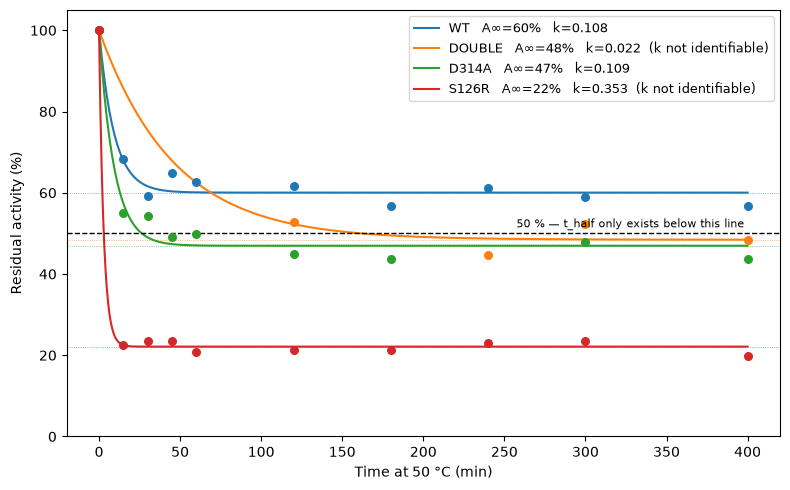

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
tt = np.linspace(0, 400, 500)

for f in sorted(fits, key=lambda f: -f.a_inf):
    g = df[df.variant == f.variant]
    pts = ax.scatter(g.time_min, g.activity_pct, s=30, zorder=3)
    color = pts.get_facecolor()[0]

    label = f"{f.variant}   A∞={f.a_inf:.0f}%   k={f.k:.3f}"
    if not f.k_identifiable:
        label += "  (k not identifiable)"

    ax.plot(tt, residual_activity(tt, f.k, f.a_inf), color=color, label=label)
    ax.axhline(f.a_inf, color=color, lw=0.6, ls=":", alpha=0.7)

ax.axhline(50, ls="--", c="k", lw=1)
ax.text(398, 51.5, "50 % — t_half only exists below this line",
        ha="right", fontsize=8)

ax.set_xlabel("Time at 50 °C (min)")
ax.set_ylabel("Residual activity (%)")
ax.set_ylim(0, 105)
ax.legend(fontsize=9)

fig.tight_layout()
fig.savefig("../docs/resultados/01-inactivation-fits.png", dpi=150)

## 4. Two observations to take back to the lab

**WT and D314A inactivate at the same rate.** Their fitted `k` are 0.108 and
0.109, with intervals that overlap almost completely. What differs is only the
plateau: 60 % vs 47 %. D314A does not change how fast the enzyme inactivates, it
changes what fraction survives. Those are different physical claims.

**The double mutant behaves like D314A alone, not like the sum.** S126R on its
own collapses to 22 %, but S126R combined with D314A sits at 48 %, within error
of D314A alone at 47 %. The effects are not additive. Notebook 02 quantifies
that non-additivity.

## 5. Known limit of the sampling grid

The first measured point is at 15 min. For the fastest-decaying variant the
plateau is already reached by then, so `k` is not identifiable from this grid:
the fit returns whatever the optimiser lands on and the bootstrap interval
blows up. Resolving `k` for S126R would need early points (1, 2, 5, 10 min).
`A_inf` is unaffected and stays well determined for all four.

In [13]:
from pathlib import Path

out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)

summary = table.copy()
summary.to_csv(out_dir / "inactivation_fits.csv", index=False)
summary

,variant,n_points,k,a_inf,tau,t_half,k_identifiable
0,WT,10,0.108200,60.041928,9.242186,undefined,True
1,DOUBLE,5,0.021650,48.444166,46.188999,161.69,False
2,D314A,9,0.108553,46.964029,9.212067,26.35,True
3,S126R,10,0.352960,22.123017,2.833181,2.91,False
